# Outlier Detection & Treatment on Real Air-Quality Sensor Data

**Goal:** compare at least three outlier detectors, justify feature treatments, measure the effect on model performance, and discuss the risk of removing rare-but-important pollution events.

**Original dataset:** UCI Air Quality (9,358 hourly measurements, Italy, 2004–2005). Download `AirQualityUCI.csv` from [the official UCI page](https://archive.ics.uci.edu/dataset/360/air+quality) and place it beside this notebook.

> The dataset uses `-200` as a missing-value code. The notebook converts it to missing data, uses a chronological split, and never caps or deletes extreme values in the target `CO(GT)`.


## 1. Imports and load the original dataset

In [4]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.preprocessing import StandardScaler, PowerTransformer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

DATA_PATHS = [Path("AirQualityUCI.csv"), Path("data/AirQualityUCI.csv")]
data_path = next((p for p in DATA_PATHS if p.exists()), None)
if data_path is None:
    raise FileNotFoundError("Download AirQualityUCI.csv from the UCI link above and place it beside the notebook.")

df = pd.read_csv(data_path, sep=";", decimal=",").dropna(axis=1, how="all")
df.columns = [c.strip() for c in df.columns]
df = df.replace(-200, np.nan)

# In the original UCI CSV, times look like 18.00.00, not 18:00:00.
clean_time = df["Time"].astype(str).str.strip().str.replace(".", ":", regex=False)
df["timestamp"] = pd.to_datetime(
    df["Date"].astype(str).str.strip() + " " + clean_time,
    dayfirst=True, errors="coerce"
)
df = df.dropna(subset=["timestamp"]).sort_values("timestamp").reset_index(drop=True)
if df.empty:
    raise ValueError("No timestamps parsed. Check that the original UCI Date and Time columns were loaded correctly.")

print("Dataset shape:", df.shape)
display(df.head())
print("\nMissing values after converting -200 to NaN:")
display(df.isna().sum().sort_values(ascending=False).head(10).to_frame("missing_count"))

Dataset shape: (9357, 16)


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,timestamp
0,10/03/2004,18.00.00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578,2004-03-10 18:00:00
1,10/03/2004,19.00.00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255,2004-03-10 19:00:00
2,10/03/2004,20.00.00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502,2004-03-10 20:00:00
3,10/03/2004,21.00.00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867,2004-03-10 21:00:00
4,10/03/2004,22.00.00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888,2004-03-10 22:00:00



Missing values after converting -200 to NaN:


,missing_count
NMHC(GT),8443
CO(GT),1683
NO2(GT),1642
NOx(GT),1639
C6H6(GT),366
PT08.S2(NMHC),366
PT08.S3(NOx),366
PT08.S1(CO),366
T,366
RH,366


## 2. Choose target and use a chronological train/test split
We predict `CO(GT)` from the other numerical sensor, pollutant, and weather features. Earlier readings train the model; later readings test it. This is more realistic than randomly mixing time points.

In [5]:
TARGET = "CO(GT)"
drop_columns = {TARGET, "Date", "Time", "timestamp"}
features = [c for c in df.select_dtypes(include=np.number).columns if c not in drop_columns]

model_data = df.dropna(subset=[TARGET]).copy()
X = model_data[features].replace([np.inf, -np.inf], np.nan)
y = model_data[TARGET].astype(float)

split = int(0.80 * len(model_data))
X_train, X_test = X.iloc[:split].copy(), X.iloc[split:].copy()
y_train, y_test = y.iloc[:split], y.iloc[split:]

print(f"Valid target rows: {len(model_data):,}")
print(f"Features ({len(features)}): {features}")
print(f"Train rows: {len(X_train):,}; test rows: {len(X_test):,}")

Valid target rows: 7,674
Features (12): ['PT08.S1(CO)', 'NMHC(GT)', 'C6H6(GT)', 'PT08.S2(NMHC)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'AH']
Train rows: 6,139; test rows: 1,535


## 3. Outlier detection: IQR, Isolation Forest, and LOF
Each method sees the same training rows. IQR flags a row if any feature lies outside its 1.5×IQR range. Isolation Forest looks for observations that are easy to isolate. LOF identifies observations with unusually low local density. These methods find unusual observations; they do **not** prove the observations are errors.

In [6]:
# Impute and scale for distance/tree detectors; fit on training data only.
detector_prep = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
X_train_scaled = detector_prep.fit_transform(X_train)
X_train_imputed = SimpleImputer(strategy="median").fit_transform(X_train)

q1 = np.nanpercentile(X_train.to_numpy(), 25, axis=0)
q3 = np.nanpercentile(X_train.to_numpy(), 75, axis=0)
iqr = q3 - q1
iqr_flags = ((X_train_imputed < (q1 - 1.5 * iqr)) |
             (X_train_imputed > (q3 + 1.5 * iqr))).any(axis=1)

iso_flags = IsolationForest(contamination=0.03, random_state=42).fit_predict(X_train_scaled) == -1
lof_flags = LocalOutlierFactor(n_neighbors=25, contamination=0.03).fit_predict(X_train_scaled) == -1

flags = pd.DataFrame({
    "IQR_any_feature": iqr_flags,
    "IsolationForest": iso_flags,
    "LocalOutlierFactor": lof_flags
}, index=X_train.index)

summary = pd.DataFrame({
    "method": flags.columns,
    "flagged_rows": [int(flags[c].sum()) for c in flags.columns],
    "flagged_percent": [round(100 * flags[c].mean(), 2) for c in flags.columns]
})
display(summary)
display(flags.head())

,method,flagged_rows,flagged_percent
0,IQR_any_feature,681,11.09
1,IsolationForest,185,3.01
2,LocalOutlierFactor,185,3.01


,IQR_any_feature,IsolationForest,LocalOutlierFactor
0,False,False,False
1,False,False,False
2,False,False,False
3,False,False,False
4,False,False,False


,IQR_any_feature,IsolationForest,LocalOutlierFactor
IQR_any_feature,681.0,183.0,47.0
IsolationForest,183.0,185.0,23.0
LocalOutlierFactor,47.0,23.0,185.0


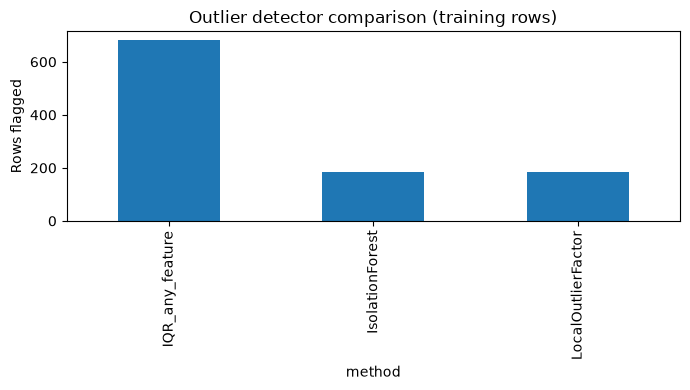

In [7]:
# Pairwise overlap: how many rows were flagged by both methods?
overlap = pd.DataFrame(index=flags.columns, columns=flags.columns, dtype=int)
for a in flags.columns:
    for b in flags.columns:
        overlap.loc[a, b] = int((flags[a] & flags[b]).sum())
display(overlap)

summary.plot(x="method", y="flagged_rows", kind="bar", legend=False, figsize=(7, 4))
plt.ylabel("Rows flagged")
plt.title("Outlier detector comparison (training rows)")
plt.tight_layout()
plt.show()

## 4. Feature-by-feature treatment decision

| Feature group | Initial decision | Why |
|---|---|---|
| CO(GT), the target | **Retain extreme target values**; drop only rows where target is missing | A pollution spike may be the event we want the model to learn. Capping target labels can teach the model that severe pollution never exceeds a ceiling. |
| Gas concentration features (CO, NMHC, benzene, NOx, NO2 where used as predictors) | Compare no treatment, capping, and transformation | Right tails can contain measurement noise, but can also be genuine pollution episodes. |
| Sensor-response features (`PT08...`) | Compare no treatment, capping, and transformation | Large readings may be sensor noise or meaningful responses; do not delete rows solely because a detector flags them. |
| Weather (`T`, `RH`, `AH`) | Retain by default; impute missing values only | Unusual weather may be real and contextually important. Capping requires evidence, not just a statistical flag. |
| Missing values (`-200` in the source) | Convert to missing and impute predictors within each model pipeline | `-200` is the dataset's missing-value code, not a real physical reading. |

For the modelling comparison, capping thresholds are learned from the **training period only**. The test period is never used to learn thresholds or transformations.

In [8]:
# Learn 1st/99th percentile caps on training predictors only.
caps = {}
for col in features:
    values = X_train[col].dropna()
    caps[col] = (values.quantile(0.01), values.quantile(0.99))

def cap_predictors(frame):
    result = frame.copy()
    for col, (low, high) in caps.items():
        result[col] = result[col].clip(low, high)
    return result

X_train_capped = cap_predictors(X_train)
X_test_capped = cap_predictors(X_test)

def evaluate_model(name, train_x, test_x, use_power_transform=False):
    steps = [("imputer", SimpleImputer(strategy="median"))]
    if use_power_transform:
        steps.append(("power", PowerTransformer(method="yeo-johnson", standardize=False)))
    steps.extend([("scale", StandardScaler()), ("model", Ridge(alpha=1.0))])
    model = Pipeline(steps)
    model.fit(train_x, y_train)
    prediction = model.predict(test_x)
    return {
        "treatment": name,
        "MAE (lower is better)": mean_absolute_error(y_test, prediction),
        "RMSE (lower is better)": mean_squared_error(y_test, prediction) ** 0.5,
        "R2 (higher is better)": r2_score(y_test, prediction)
    }, prediction

results = []
predictions = {}
for name, train_x, test_x, power in [
    ("A: impute only", X_train, X_test, False),
    ("B: cap predictors at train 1st/99th pct", X_train_capped, X_test_capped, False),
    ("C: Yeo-Johnson transform predictors", X_train, X_test, True)
]:
    row, pred = evaluate_model(name, train_x, test_x, power)
    results.append(row)
    predictions[name] = pred

performance = pd.DataFrame(results)
display(performance.round(4))

,treatment,MAE (lower is better),RMSE (lower is better),R2 (higher is better)
0,A: impute only,0.3142,0.4959,0.8640
1,B: cap predictors at train 1st/99th pct,0.3141,0.5033,0.8599
2,C: Yeo-Johnson transform predictors,0.4134,0.6014,0.7999


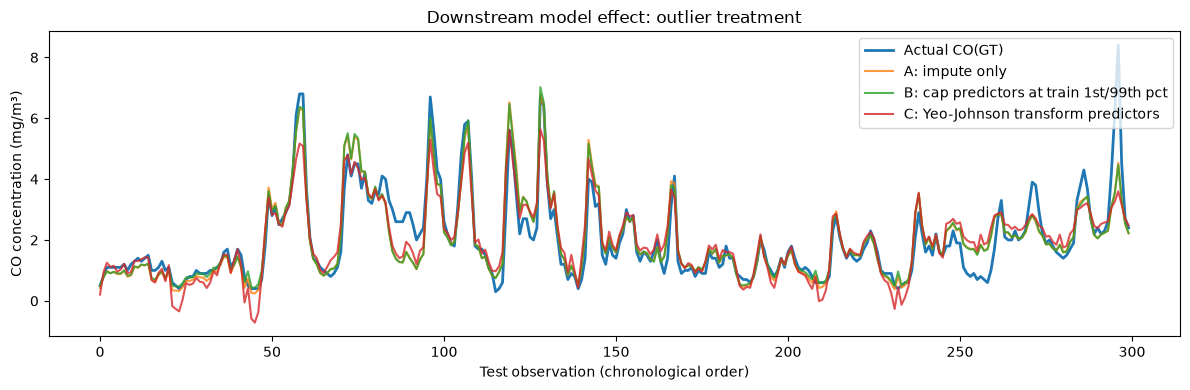

In [9]:
# Compare predictions on the first 300 rows of the chronological test period.
n = min(300, len(y_test))
plt.figure(figsize=(12, 4))
plt.plot(np.arange(n), y_test.iloc[:n].to_numpy(), label="Actual CO(GT)", linewidth=2)
for name, pred in predictions.items():
    plt.plot(np.arange(n), pred[:n], label=name, alpha=0.8)
plt.xlabel("Test observation (chronological order)")
plt.ylabel("CO concentration (mg/m³)")
plt.title("Downstream model effect: outlier treatment")
plt.legend()
plt.tight_layout()
plt.show()

## 5. Risk discussion and final decision

**Main risk:** a real high-pollution episode can be statistically rare and still be the most important observation in the dataset. Deleting all flagged rows or clipping the target would risk erasing precisely the events a monitoring model should anticipate.

**Decision rule:** use the held-out chronological metrics to compare the three treatments, but do not select a treatment based only on a tiny metric improvement. If capping improves MAE/RMSE, inspect which predictor readings were capped and whether related pollutants, other sensors, and timestamps support a genuine event. Prefer retaining the raw extreme reading when it is physically plausible. If a reading is confirmed to be a sensor fault, correct or mark it using sensor-quality evidence rather than a global statistical rule.

**How to report results:** state which method flags the most rows, how much overlap the detectors have, which treatment has the best test MAE/RMSE/R², and why that result does (or does not) justify treatment. The notebook intentionally computes the actual numbers from the downloaded original dataset rather than inventing results.

## 6. Save tables and plots

Run this final cell after reviewing results. It writes comparison CSVs and figures into `outputs/`.

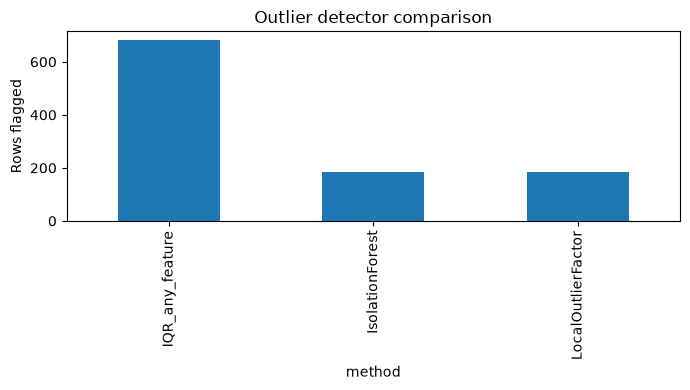

Saved outputs to: /Users/wajeehaahmad/Documents/ML_assignments/ML_Advanced_Assignment/PART_A3/outputs


In [10]:
from pathlib import Path
OUT = Path("outputs")
OUT.mkdir(exist_ok=True)

flags.to_csv(OUT / "detector_flags_train.csv", index=False)
summary.to_csv(OUT / "detector_summary.csv", index=False)
overlap.to_csv(OUT / "detector_overlap_counts.csv")
performance.to_csv(OUT / "model_performance_comparison.csv", index=False)

feature_decisions = pd.DataFrame({
    "feature": features,
    "recommended_initial_treatment": [
        "Retain; impute missing values; compare cap/transform variants"
        if not any(token in c.lower() for token in [" t", "rh", "ah"])
        else "Retain as-is; impute missing values; avoid automatic clipping"
        for c in features
    ],
    "risk_note": [
        "An extreme value may be a genuine pollution/sensor event; do not delete based on detector flag alone."
        for _ in features
    ]
})
feature_decisions.to_csv(OUT / "feature_treatment_decisions.csv", index=False)

summary.plot(x="method", y="flagged_rows", kind="bar", legend=False, figsize=(7, 4))
plt.ylabel("Rows flagged")
plt.title("Outlier detector comparison")
plt.tight_layout()
plt.savefig(OUT / "detector_comparison.png", dpi=150)
plt.show()

print("Saved outputs to:", OUT.resolve())